# Education level per municipality

This notebook maps the share of highly and low educated residents in all Dutch municipalities.

**Definitions** (persons aged 15 to 75):
- **Highly educated:** hbo or wo as highest completed level
- **Low educated:** basisonderwijs, vmbo or mbo-1 as highest completed level
- Shares are calculated as a percentage of all persons aged 15 to 75 with a known education level (low + middle + high).

**Required files:**
- `data/processed/education_per_municipality.csv`: share of highly and low educated residents per municipality, made by notebook 0.2
- `data/raw/gemeenten_2024.gpkg`: municipal boundaries from CBS/PDOK, 2024 municipal division
- `data/processed/chargingpoints_households_income.csv`: made by notebook 1, only used to check that the names match

**Output:**
- `figures/map_education_per_municipality.png`

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load the data

Notebook 0.2 has already calculated the shares. They are only calculated when all three education levels are known. For Rozendaal, CBS does not publish the number of low educated persons (too few residents), so its shares are empty instead of being calculated from an incomplete total.

In [2]:
education = pd.read_csv("../data/processed/education_per_municipality.csv")

print("Number of municipalities:", len(education))
print("Municipalities without a share:", education.loc[education["highly_educated_pct"].isna(), "municipality"].tolist())
display(education[["highly_educated_pct", "low_educated_pct"]].describe().round(1))

# Check: does every municipality match the charging point data? Both lines should print set()
charging = pd.read_csv("../data/processed/chargingpoints_households_income.csv")
print("Only in the education data:", set(education["municipality"]) - set(charging["municipality"]))
print("Only in the charging data:", set(charging["municipality"]) - set(education["municipality"]))

Number of municipalities: 342
Municipalities without a share: ['Rozendaal']


,highly_educated_pct,low_educated_pct
count,341.0,341.0
mean,30.4,26.3
std,8.0,4.2
min,12.4,15.5
25%,25.1,23.8
50%,28.7,26.4
75%,33.4,29.2
max,58.4,37.1


Only in the education data: set()
Only in the charging data: set()


## 2. Join the data to the map

The boundary file uses CBS names, for example *'s-Gravenhage* instead of *Den Haag*. We convert these to the spelling of the charging point file, so the map can be joined on the municipality name.

In [3]:
municipalities = gpd.read_file("../data/raw/gemeenten_2024.gpkg", layer="gemeente_gegeneraliseerd")

# Names in the boundary file (left) -> spelling of the charging point file (right)
map_name_mapping = {
    "'s-Gravenhage": "Den Haag",
    "Beek (L.)": "Beek",
    "Hengelo (O.)": "Hengelo",
    "Laren (NH.)": "Laren",
    "Middelburg (Z.)": "Middelburg",
    "Rijswijk (ZH.)": "Rijswijk",
    "Stein (L.)": "Stein",
}
municipalities["municipality"] = municipalities["statnaam"].replace(map_name_mapping)

map_gdf = municipalities.merge(education, on="municipality", how="left")

# Check: should print 0 and 1 (Rozendaal)
print("Municipalities not found in the data:", (~municipalities["municipality"].isin(education["municipality"])).sum())
print("Municipalities without a share:", map_gdf["highly_educated_pct"].isna().sum())

Municipalities not found in the data: 0
Municipalities without a share: 1


## 3. Create the maps

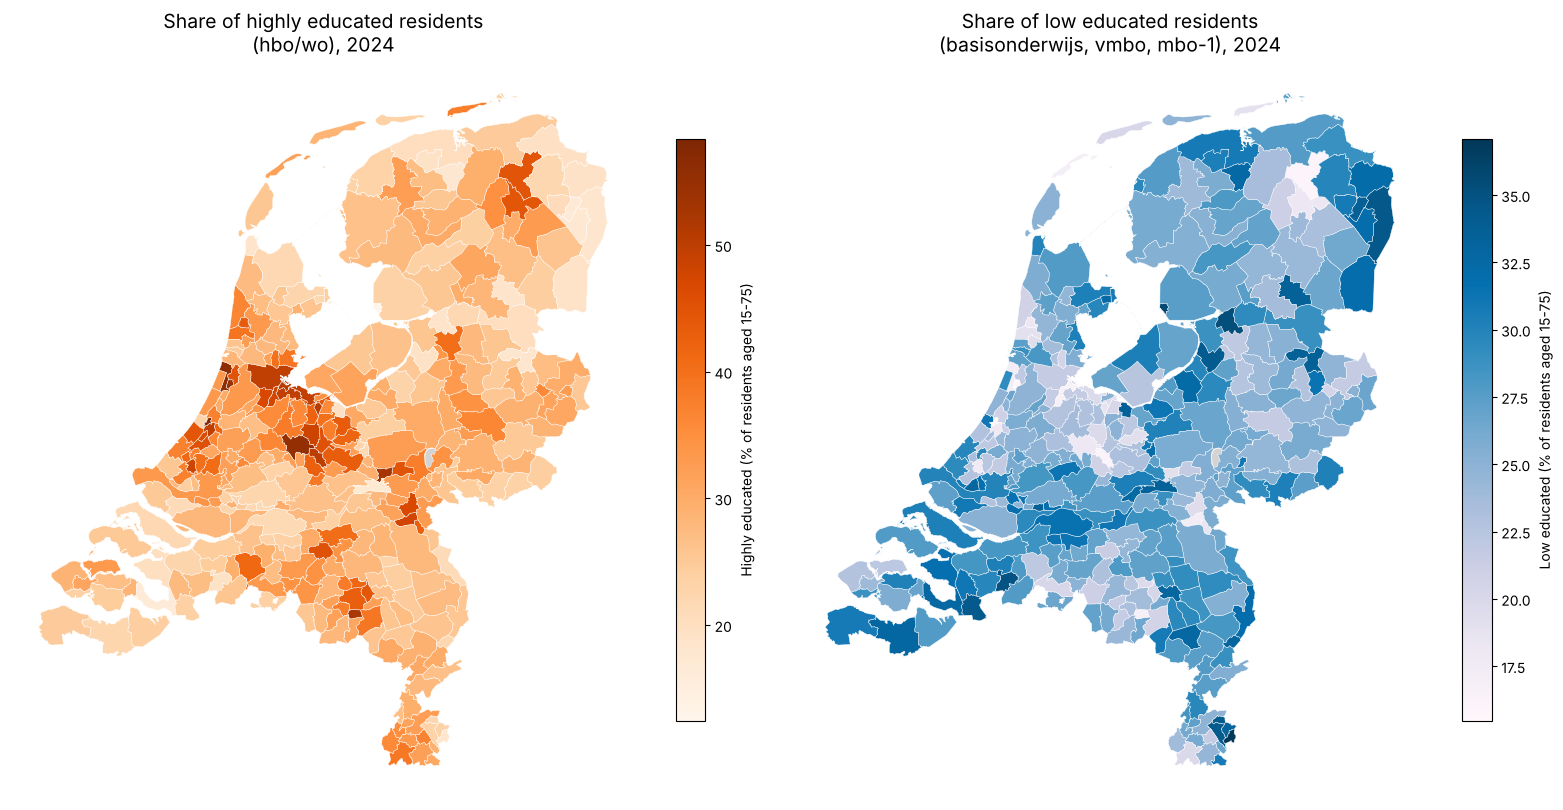

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 10))

map_gdf.plot(
    column="highly_educated_pct",
    cmap="Oranges",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Highly educated (% of residents aged 15-75)", "shrink": 0.6},
    ax=axes[0],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[0].set_title("Share of highly educated residents\n(hbo/wo), 2024", fontsize=14)
axes[0].axis("off")

map_gdf.plot(
    column="low_educated_pct",
    cmap="PuBu",
    linewidth=0.3,
    edgecolor="white",
    legend=True,
    legend_kwds={"label": "Low educated (% of residents aged 15-75)", "shrink": 0.6},
    ax=axes[1],
    missing_kwds={"color": "lightgrey", "label": "No data"},
)
axes[1].set_title("Share of low educated residents\n(basisonderwijs, vmbo, mbo-1), 2024", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
os.makedirs("../figures", exist_ok=True)
plt.savefig("../figures/map_education_per_municipality.png", dpi=200)
plt.show()